# Correção de séries pluviométricas pelo método da curva de dupla massa

Este notebook **não refaz a construção das curvas de dupla massa** e não seleciona novamente as estações de apoio. Ele parte diretamente de `dados_dupla_massa.csv`.

A abordagem é **semiautomática**: o Python calcula regressões, inclinações, fatores, correções, diagnósticos, gráficos e auditoria; o pesquisador interpreta as curvas e registra as decisões finais em `DECISOES`.

Uma mudança de inclinação **não é tratada automaticamente como prova de erro**. A decisão de corrigir deve considerar metadados, histórico da estação, comportamento de estações vizinhas e interpretação hidrológica.

## 00 — Bibliotecas e configurações

In [95]:
from pathlib import Path
from zoneinfo import ZoneInfo
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 180)

ARQUIVO_ENTRADA = Path(
    r"A:\Codigo\UNIPLU-BR\2. Analise_basin\resultados_consistencia"
    r"\basin_86500000_2809_131052\dupla_massa\dados_dupla_massa.csv"
)
DIRETORIO_SAIDA = ARQUIVO_ENTRADA.parent / 'correcao_dupla_massa'
DIRETORIO_GRAFICOS = DIRETORIO_SAIDA / 'graficos'

SEP=';'; DECIMAL='.'; ENCODING='utf-8-sig'; FORMATO_DATA='%Y-%m'
MODO_INSPECAO = True
MODO_PROCESSAMENTO = True
ESTACAO_INSPECAO = None
ANOTAR_CADA_N_MESES = 24      # 0/None = não anotar
MIN_OBSERVACOES_SEGMENTO = 3
PERMITIR_CORRIGIR_SEGMENTO_REFERENCIA = False
FUSO_AUDITORIA = 'America/Sao_Paulo'

# Convenção única: a própria data de ruptura pertence ao segmento ANTERIOR.
DATA_RUPTURA_PERTENCE_AO_SEGMENTO_ANTERIOR = True

ARQ_DADOS_CORRIGIDOS = '01_dados_dupla_massa_corrigidos.csv'
ARQ_AUDITORIA = '02_auditoria_correcao_dupla_massa.csv'
ARQ_DIAGNOSTICO = '03_diagnostico_segmentos.csv'

## 01 — Leitura do CSV

Os códigos de estação e `estacoes_apoio` são preservados como **texto**. O DataFrame `df_original` não será sobrescrito.

In [96]:
COLUNAS_OBRIGATORIAS = [
    'estacao_alvo','data','n_apoios','estacoes_apoio',
    'precipitacao_alvo','precipitacao_regional','acumulado_alvo','acumulado_regional'
]

def carregar_dados(caminho):
    caminho = Path(caminho)
    if not caminho.exists():
        raise FileNotFoundError(f'Arquivo não encontrado: {caminho}\nConfira ARQUIVO_ENTRADA.')
    df = pd.read_csv(
        caminho, sep=SEP, decimal=DECIMAL, encoding=ENCODING,
        dtype={'estacao_alvo':'string','data':'string','estacoes_apoio':'string'},
        na_values=['NaN','nan','NA','N/A','null','None',''], keep_default_na=True
    )
    df.columns=[str(x) for x in df.columns]
    falt=[x for x in COLUNAS_OBRIGATORIAS if x not in df.columns]
    if falt: raise ValueError(f'Colunas obrigatórias ausentes: {falt}')
    df['estacao_alvo']=df['estacao_alvo'].astype('string').str.strip()
    df['estacoes_apoio']=df['estacoes_apoio'].astype('string')
    df['data']=pd.to_datetime(df['data'], format=FORMATO_DATA, errors='coerce')
    for col in ['n_apoios','precipitacao_alvo','precipitacao_regional','acumulado_alvo','acumulado_regional']:
        df[col]=pd.to_numeric(df[col], errors='coerce')
    return df.sort_values(['estacao_alvo','data'], kind='stable').reset_index(drop=True)

df_original = carregar_dados(ARQUIVO_ENTRADA)
print(f'Linhas: {len(df_original):,} | Estações: {df_original.estacao_alvo.nunique():,}')

Linhas: 9,494 | Estações: 19


## 02 — Verificação da estrutura

As validações abaixo são automáticas e apenas verificam a integridade do arquivo. Elas **não decidem rupturas**.

In [97]:
def validar_dados(df):
    erros=[]; avisos=[]
    if df['estacao_alvo'].isna().any(): erros.append('códigos de estação alvo ausentes')
    if df['data'].isna().any(): erros.append('datas inválidas')
    if df.duplicated(['estacao_alvo','data'], keep=False).any(): erros.append('pares estação/data duplicados')
    for col in ['precipitacao_alvo','precipitacao_regional','acumulado_alvo','acumulado_regional']:
        if df[col].isna().any(): erros.append(f"'{col}' contém NaN")
    if (df['precipitacao_alvo']<0).any(): erros.append('precipitação alvo negativa')
    if (df['precipitacao_regional']<0).any(): erros.append('precipitação regional negativa')
    for est,g in df.groupby('estacao_alvo', sort=False):
        g=g.sort_values('data')
        if not g['data'].is_monotonic_increasing: erros.append(f'{est}: datas fora de ordem')
        if (g['acumulado_alvo'].diff().dropna() < -1e-10).any(): erros.append(f'{est}: acumulado alvo diminui')
        if (g['acumulado_regional'].diff().dropna() < -1e-10).any(): erros.append(f'{est}: acumulado regional diminui')
        if not np.allclose(g['precipitacao_alvo'].cumsum(), g['acumulado_alvo'], rtol=1e-8, atol=1e-8):
            avisos.append(f'{est}: acumulado_alvo do CSV difere de cumsum(precipitacao_alvo)')
        if not np.allclose(g['precipitacao_regional'].cumsum(), g['acumulado_regional'], rtol=1e-8, atol=1e-8):
            avisos.append(f'{est}: acumulado_regional do CSV difere de cumsum(precipitacao_regional)')
    if erros: raise ValueError('Falhas estruturais:\n- ' + '\n- '.join(erros))
    for a in avisos: warnings.warn(a)
    return {'n_erros':0,'n_avisos':len(avisos)}

relatorio_validacao_inicial=validar_dados(df_original)
df_original_snapshot=df_original.copy(deep=True)
print(relatorio_validacao_inicial)

{'n_erros': 0, 'n_avisos': 0}


## 03 — Listagem das estações alvo

In [98]:
estacoes_alvo=df_original['estacao_alvo'].astype(str).drop_duplicates().tolist()
resumo_estacoes=(df_original.groupby('estacao_alvo',sort=False)
    .agg(n_meses=('data','size'),data_inicial=('data','min'),data_final=('data','max'),
         n_apoios_min=('n_apoios','min'),n_apoios_max=('n_apoios','max')).reset_index())
display(resumo_estacoes)

,estacao_alvo,n_meses,data_inicial,data_final,n_apoios_min,n_apoios_max
0,2751007,536,1980-01-01,2024-12-01,3,3
1,2751017,536,1980-01-01,2024-12-01,3,3
2,2851003,540,1980-01-01,2024-12-01,3,3
3,2851005,396,1980-01-01,2012-12-01,3,3
4,2851020,526,1980-01-01,2024-12-01,3,3
5,2851021,540,1980-01-01,2024-12-01,3,3
6,2851022,540,1980-01-01,2024-12-01,3,3
7,2851024,540,1980-01-01,2024-12-01,3,3
8,2851028,499,1980-01-01,2024-12-01,3,3
9,2851043,536,1980-01-01,2024-12-01,3,3


## 04–05 — Inspeção visual da curva original

O modo de inspeção é apenas exploratório. A decisão reproduzível deve ficar em `DECISOES`.

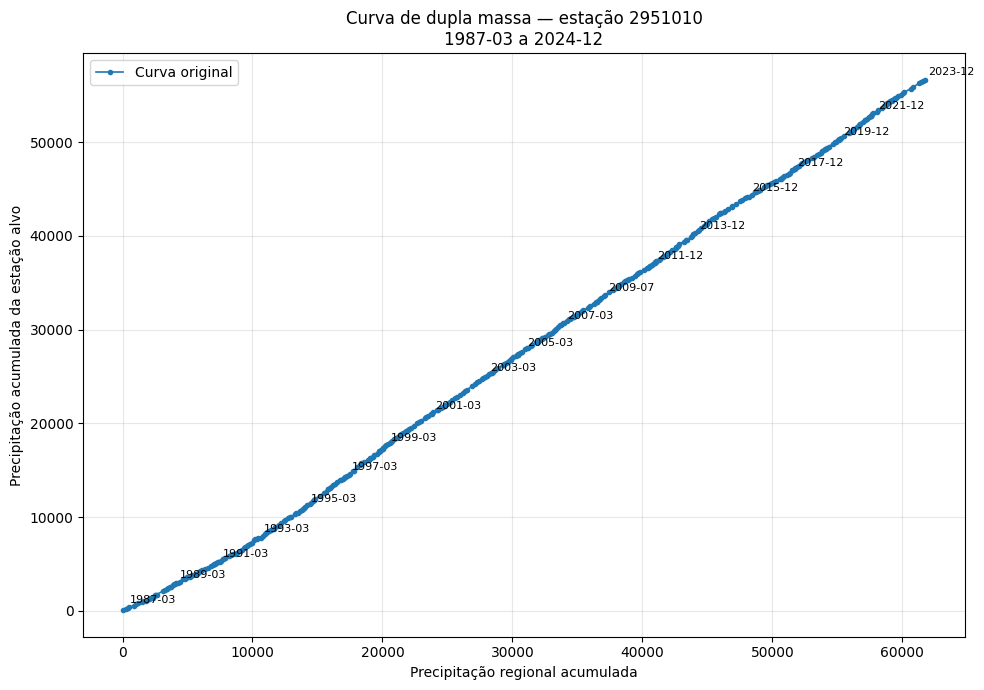

In [99]:
def dados_estacao(df, estacao):
    g=df.loc[df['estacao_alvo'].astype(str)==str(estacao)].copy()
    if g.empty: raise KeyError(f'Estação {estacao} não encontrada')
    return g.sort_values('data').reset_index(drop=True)

def anotar_datas(ax,g,xcol,ycol,a_cada=24):
    if not a_cada: return
    for i in range(0,len(g),int(a_cada)):
        r=g.iloc[i]
        ax.annotate(r['data'].strftime('%Y-%m'),(r[xcol],r[ycol]),xytext=(5,5),textcoords='offset points',fontsize=8)

def plotar_dupla_massa_original(estacao, anotar_cada=ANOTAR_CADA_N_MESES):
    g=dados_estacao(df_original, estacao)
    fig,ax=plt.subplots(figsize=(10,7))
    ax.plot(g['acumulado_regional'],g['acumulado_alvo'],marker='o',markersize=3,linewidth=1.2,label='Curva original')
    anotar_datas(ax,g,'acumulado_regional','acumulado_alvo',anotar_cada)
    ax.set_title(f"Curva de dupla massa — estação {estacao}\n{g.data.min():%Y-%m} a {g.data.max():%Y-%m}")
    ax.set_xlabel('Precipitação regional acumulada'); ax.set_ylabel('Precipitação acumulada da estação alvo')
    ax.grid(True,alpha=.3); ax.legend(); fig.tight_layout(); return fig,ax

if ESTACAO_INSPECAO is None and estacoes_alvo: ESTACAO_INSPECAO=estacoes_alvo[16]
if MODO_INSPECAO and ESTACAO_INSPECAO is not None:
    plotar_dupla_massa_original(str(ESTACAO_INSPECAO)); plt.show()

## 06 — DECISÕES DO PESQUISADOR

**Convenção:** a data de ruptura pertence ao segmento anterior. Assim, `"1998-06"` faz o segmento 1 terminar em 1998-06 e o segmento 2 começar em 1998-07.

- `rupturas=[]`: nenhuma correção necessária;
- `aprovado=False`: a ruptura foi analisada, mas a correção foi rejeitada;
- são suportadas múltiplas rupturas.

In [100]:
# ========================== DECISÕES DO PESQUISADOR ==========================
# Exemplo (substitua pelos seus códigos reais):
DECISOES = {
   '2951010': {'rupturas':['1992-04'],'segmento_referencia':2,'segmentos_corrigir':[1],
               'aprovado':True,'observacao':'Mudança persistente após 1992-04'},
#   '2851003': {'rupturas':['1987-12','2002-03'],'segmento_referencia':2,'segmentos_corrigir':[1,3],
#               'aprovado':True,'observacao':''},
#   '2851019': {'rupturas':['2001-04'],'segmento_referencia':1,'segmentos_corrigir':[2],
#               'aprovado':False,'observacao':'Correção rejeitada após inspeção'},
#   '2851031': {'rupturas':[],'segmento_referencia':1,'segmentos_corrigir':[],
#               'aprovado':True,'observacao':'Curva considerada consistente'},
}
# DECISOES = {}

## 07 — Segmentação e validação das decisões

A ruptura precisa existir exatamente na série mensal da estação. Datas duplicadas, fora de ordem ou segmentos inexistentes geram erro explícito.

In [101]:
def normalizar_rupturas(rupturas):
    if rupturas is None: return []
    s=pd.Series(list(rupturas),dtype='string')
    d=pd.to_datetime(s,format='%Y-%m',errors='coerce')
    if d.isna().any(): raise ValueError(f'Datas de ruptura inválidas: {s[d.isna()].tolist()}')
    return list(pd.DatetimeIndex(d))

def validar_decisao(estacao,decisao,g):
    if not isinstance(decisao,dict): raise TypeError(f'{estacao}: decisão deve ser dicionário')
    rupt=normalizar_rupturas(decisao.get('rupturas',[])); erros=[]
    if len(set(rupt))!=len(rupt): erros.append('rupturas duplicadas')
    if rupt!=sorted(rupt): erros.append('rupturas fora de ordem')
    datas=set(pd.DatetimeIndex(g['data']))
    for r in rupt:
        if r not in datas: erros.append(f'ruptura {r:%Y-%m} não existe na série')
    nseg=len(rupt)+1
    try: ref=int(decisao.get('segmento_referencia',1))
    except: ref=-1; erros.append('segmento_referencia não inteiro')
    if ref<1 or ref>nseg: erros.append(f'segmento_referencia {ref} inexistente (1..{nseg})')
    try: corr=[int(x) for x in decisao.get('segmentos_corrigir',[])]
    except: corr=[]; erros.append('segmentos_corrigir inválido')
    if len(set(corr))!=len(corr): erros.append('segmentos_corrigir duplicados')
    inv=[x for x in corr if x<1 or x>nseg]
    if inv: erros.append(f'segmentos_corrigir inexistentes: {inv}')
    if ref in corr and not PERMITIR_CORRIGIR_SEGMENTO_REFERENCIA:
        erros.append('segmento de referência também marcado para correção')
    if erros: raise ValueError(f"{estacao}: " + '; '.join(erros))
    return {'rupturas':rupt,'segmento_referencia':ref,'segmentos_corrigir':corr,
            'aprovado':bool(decisao.get('aprovado',False)),
            'observacao':str(decisao.get('observacao','')),'n_segmentos':nseg}

def criar_segmentos(g,rupturas):
    out=g.copy(); datas=pd.DatetimeIndex(out['data']); seg=np.ones(len(out),dtype=int)
    for r in rupturas: seg += (datas>r).astype(int)  # a ruptura fica no segmento anterior
    out['segmento']=seg; return out

## 08 — Inclinações locais por segmento

Para segmentos posteriores são usadas coordenadas relativas ao acumulado **imediatamente anterior ao início do segmento**:

\[
X_{rel}=X-X_0,\qquad Y_{rel}=Y-Y_0
\]

No primeiro segmento, \(X_0=Y_0=0\). Isso faz o primeiro mês de cada trecho participar integralmente do ajuste e evita carregar para a interpretação local o grande acumulado formado antes do segmento. Com regressão contendo intercepto, a translação não altera matematicamente a inclinação, mas melhora a interpretação e o condicionamento numérico.

In [102]:
def regressao_linear(x,y,min_obs=MIN_OBSERVACOES_SEGMENTO):
    x=np.asarray(x,float); y=np.asarray(y,float)
    if len(x)<min_obs: raise ValueError(f'observações insuficientes: n={len(x)} < {min_obs}')
    if not np.isfinite(x).all() or not np.isfinite(y).all(): raise ValueError('valores não finitos')
    if np.isclose(np.var(x),0): raise ValueError('variância de X igual a zero')
    m,b=np.polyfit(x,y,1); yh=m*x+b
    ssr=float(np.sum((y-yh)**2)); sst=float(np.sum((y-np.mean(y))**2))
    if np.isclose(sst,0): raise ValueError('variância de Y igual a zero')
    r2=1-ssr/sst
    if not(np.isfinite(m) and np.isfinite(b) and np.isfinite(r2)): raise ValueError('ajuste não finito')
    return float(m),float(b),float(r2),int(len(x))

def baseline_segmento(g,seg,xcol,ycol):
    pos=np.flatnonzero(g['segmento'].to_numpy()==seg)
    if len(pos)==0: raise ValueError(f'segmento {seg} vazio')
    p0=int(pos[0])
    if p0==0: return 0.0,0.0
    ant=g.iloc[p0-1]; return float(ant[xcol]),float(ant[ycol])

def calcular_inclinacoes(g,ycol,xcol='acumulado_regional'):
    rows=[]
    for seg in sorted(g['segmento'].unique()):
        gs=g.loc[g['segmento']==seg].copy(); x0,y0=baseline_segmento(g,int(seg),xcol,ycol)
        x=gs[xcol].to_numpy(float)-x0; y=gs[ycol].to_numpy(float)-y0
        m,b,r2,n=regressao_linear(x,y)
        rows.append({'segmento':int(seg),'data_inicio':gs.data.min(),'data_fim':gs.data.max(),
                     'x0':x0,'y0':y0,'inclinacao':m,'intercepto':b,'r2':r2,'n_observacoes':n})
    return pd.DataFrame(rows)

## 09 — Segmento de referência e fatores

Para cada segmento aprovado para correção:

\[
F=\frac{m_{ref}}{m_{seg}},\qquad \Delta(\%)=(F-1)\times100
\]

O segmento de referência é uma decisão do pesquisador.

In [103]:
def calcular_fatores(tab,ref,segs_corrigir,aprovado):
    lr=tab.loc[tab.segmento==int(ref)]
    if lr.empty: raise ValueError(f'segmento de referência {ref} inexistente')
    mref=float(lr.iloc[0].inclinacao)
    if not np.isfinite(mref) or np.isclose(mref,0): raise ValueError('inclinação de referência zero/não finita')
    f={}
    for seg in tab.segmento.astype(int):
        if aprovado and seg in segs_corrigir:
            m=float(tab.loc[tab.segmento==seg,'inclinacao'].iloc[0])
            if not np.isfinite(m) or np.isclose(m,0): raise ValueError(f'segmento {seg}: inclinação zero/não finita')
            v=mref/m
            if not np.isfinite(v) or v<=0: raise ValueError(f'segmento {seg}: fator inválido {v}')
            f[seg]=float(v)
        else: f[seg]=1.0
    return f,mref

## 10 — Aplicação da correção

A correção atua **sempre sobre `precipitacao_alvo_original`**:

\[
P_{corr}(t)=F_{seg}\,P_{orig}(t)
\]

Depois, o acumulado corrigido é reconstruído por `cumsum`. Os fatores nunca são aplicados cumulativamente sobre valores já corrigidos. Isso implementa de forma consistente a formulação clássica \(P_{corr}=P'_{acum}+(M_a/M_o)\Delta P_o\).

In [104]:
def aplicar_correcao(g,fatores,segs_corrigir,aprovado):
    x=g.copy(); x['precipitacao_alvo_original']=x['precipitacao_alvo'].astype(float)
    x['acumulado_alvo_original']=x['acumulado_alvo'].astype(float)
    x['fator_correcao']=x['segmento'].map(fatores).astype(float)
    if not aprovado: x['fator_correcao']=1.0
    x['foi_corrigido']=aprovado & x['segmento'].isin(segs_corrigir) & (~np.isclose(x['fator_correcao'],1.0))
    x['precipitacao_alvo_corrigida']=x['precipitacao_alvo_original']*x['fator_correcao']
    vals=x['precipitacao_alvo_corrigida'].to_numpy(float)
    if not np.isfinite(vals).all(): raise ValueError('precipitação corrigida não finita')
    if (vals < -1e-12).any(): raise ValueError('precipitação corrigida negativa')
    x.loc[(x.precipitacao_alvo_corrigida<0)&(x.precipitacao_alvo_corrigida>=-1e-12),'precipitacao_alvo_corrigida']=0.0
    x['acumulado_alvo_corrigido']=x['precipitacao_alvo_corrigida'].cumsum()
    return x

## 11 — Diagnóstico numérico pós-correção

In [105]:
def validar_correcao(g,orig,mref):
    cor=calcular_inclinacoes(g,'acumulado_alvo_corrigido').rename(columns={
        'inclinacao':'m_corrigido','r2':'r2_corrigido','intercepto':'intercepto_corrigido','n_observacoes':'n_observacoes_corrigido'})
    o=orig.rename(columns={'inclinacao':'m_original','r2':'r2_original','intercepto':'intercepto_original','n_observacoes':'n_observacoes_original'})
    d=o.merge(cor[['segmento','m_corrigido','r2_corrigido','intercepto_corrigido','n_observacoes_corrigido']],on='segmento')
    d['m_referencia']=float(mref)
    d['erro_relativo_antes']=np.abs(d.m_original-mref)/abs(mref)*100
    d['erro_relativo_depois']=np.abs(d.m_corrigido-mref)/abs(mref)*100
    fmap=g.groupby('segmento').fator_correcao.first().to_dict(); d['fator_aplicado']=d.segmento.map(fmap)
    return d

## 12 — Gráficos original, corrigido e antes × depois

In [106]:
def _linha_fit(g,row,ycol):
    gs=g[g.segmento==int(row.segmento)]; x=gs.acumulado_regional.to_numpy(float)
    yfit=float(row.y0)+(float(row.inclinacao)*(x-float(row.x0))+float(row.intercepto))
    return x,yfit

def _rupturas(ax,g,rupturas,ycol):
    for r in rupturas:
        z=g[g.data==r]
        if z.empty: continue
        xv=float(z.iloc[0].acumulado_regional); yv=float(z.iloc[0][ycol])
        ax.axvline(xv,linestyle='--',alpha=.45); ax.scatter([xv],[yv],marker='D',s=50,zorder=5)
        ax.annotate(f'ruptura {r:%Y-%m}',(xv,yv),xytext=(6,-14),textcoords='offset points',fontsize=8)

def plotar_curva_segmentos(g,estacao,ycol,fit,rupturas,titulo,rotulo):
    fig,ax=plt.subplots(figsize=(10,7)); ax.plot(g.acumulado_regional,g[ycol],marker='o',markersize=3,linewidth=1.2,label=rotulo)
    for _,r in fit.iterrows():
        xx,yy=_linha_fit(g,r,ycol); ax.plot(xx,yy,'--',linewidth=1.2,label=f'Regressão seg. {int(r.segmento)}')
    _rupturas(ax,g,rupturas,ycol); anotar_datas(ax,g,'acumulado_regional',ycol,ANOTAR_CADA_N_MESES)
    ax.set_title(titulo); ax.set_xlabel('Precipitação regional acumulada'); ax.set_ylabel('Precipitação acumulada da estação alvo')
    ax.grid(True,alpha=.3); ax.legend(fontsize=8); fig.tight_layout(); return fig,ax

def plotar_antes_depois(g,estacao,fo,fc,rupturas):
    fig,ax=plt.subplots(figsize=(10,7)); ax.plot(g.acumulado_regional,g.acumulado_alvo_original,label='Original',marker='o',markersize=2.5)
    ax.plot(g.acumulado_regional,g.acumulado_alvo_corrigido,label='Corrigida',marker='o',markersize=2.5)
    for _,r in fo.iterrows(): xx,yy=_linha_fit(g,r,'acumulado_alvo_original'); ax.plot(xx,yy,'--',linewidth=1,alpha=.65)
    for _,r in fc.iterrows(): xx,yy=_linha_fit(g,r,'acumulado_alvo_corrigido'); ax.plot(xx,yy,':',linewidth=1.2,alpha=.8)
    _rupturas(ax,g,rupturas,'acumulado_alvo_original')
    ax.set_title(f'Dupla massa — antes × depois — estação {estacao}'); ax.set_xlabel('Precipitação regional acumulada'); ax.set_ylabel('Precipitação acumulada da estação alvo')
    ax.grid(True,alpha=.3); ax.legend(); fig.tight_layout(); return fig,ax


## 13 — Processamento de uma estação e auditoria

In [107]:
DATA_EXECUCAO=pd.Timestamp.now(tz=ZoneInfo(FUSO_AUDITORIA)).isoformat()

def resumo_apoios(g):
    return ' || '.join(g.estacoes_apoio.dropna().astype(str).drop_duplicates().tolist())

def processar_uma_estacao(estacao,decisao):
    g0=dados_estacao(df_original,estacao); dec=validar_decisao(str(estacao),decisao,g0); gs=criar_segmentos(g0,dec['rupturas'])
    fo=calcular_inclinacoes(gs,'acumulado_alvo'); fatores,mref=calcular_fatores(fo,dec['segmento_referencia'],dec['segmentos_corrigir'],dec['aprovado'])
    gc=aplicar_correcao(gs,fatores,dec['segmentos_corrigir'],dec['aprovado']); fc=calcular_inclinacoes(gc,'acumulado_alvo_corrigido'); dg=validar_correcao(gc,fo,mref)
    status='correcao_rejeitada' if not dec['aprovado'] else ('sem_correcao_necessaria' if len(dec['rupturas'])==0 or len(dec['segmentos_corrigir'])==0 else 'corrigida')
    rupt='|'.join(r.strftime('%Y-%m') for r in dec['rupturas']); aud=[]; apoios=resumo_apoios(gc)
    for _,r in dg.iterrows():
        seg=int(r.segmento); fator=float(r.fator_aplicado)
        aud.append({'estacao_alvo':str(estacao),'segmento':seg,'data_inicio':r.data_inicio,'data_fim':r.data_fim,'rupturas':rupt,
                    'segmento_referencia':int(dec['segmento_referencia']),'segmento_corrigido':bool(dec['aprovado'] and seg in dec['segmentos_corrigir']),
                    'inclinacao_original':float(r.m_original),'inclinacao_referencia':float(mref),'fator_correcao':fator,
                    'alteracao_percentual':(fator-1)*100,'r2_original':float(r.r2_original),'r2_pos_correcao':float(r.r2_corrigido),
                    'n_observacoes':int(r.n_observacoes_original),'aprovado':bool(dec['aprovado']),'observacao':dec['observacao'],
                    'estacoes_apoio_resumo':apoios,'n_apoios_min':int(gc.n_apoios.min()),'n_apoios_max':int(gc.n_apoios.max()),
                    'data_execucao':DATA_EXECUCAO,'status_estacao':status})
    dg['estacao_alvo']=str(estacao); dg['periodo']=dg.data_inicio.dt.strftime('%Y-%m')+' a '+dg.data_fim.dt.strftime('%Y-%m')
    dg['segmento_referencia']=int(dec['segmento_referencia']); dg['segmento_corrigido']=dec['aprovado'] & dg.segmento.isin(dec['segmentos_corrigir'])
    dg['aprovado']=bool(dec['aprovado']); dg['status_estacao']=status
    return {'dados':gc,'fit_original':fo,'fit_corrigido':fc,'diagnostico':dg,'auditoria':pd.DataFrame(aud),'decisao':dec,'status':status}

## 14 — Processamento em lote

In [108]:
def preparar_sem_correcao(g0):
    g=g0.copy(); g['precipitacao_alvo_original']=g.precipitacao_alvo.astype(float); g['acumulado_alvo_original']=g.acumulado_alvo.astype(float)
    g['segmento']=1; g['fator_correcao']=1.0; g['foi_corrigido']=False; g['precipitacao_alvo_corrigida']=g.precipitacao_alvo_original
    g['acumulado_alvo_corrigido']=g.precipitacao_alvo_corrigida.cumsum(); return g

resultados_estacoes={}; linhas=[]; auds=[]; diags=[]; erros_processamento=[]
if MODO_PROCESSAMENTO:
    for est in estacoes_alvo:
        est=str(est); g0=dados_estacao(df_original,est)
        if est not in DECISOES:
            g=preparar_sem_correcao(g0); g['status_processamento']='nao_analisada'; linhas.append(g); resultados_estacoes[est]={'status':'nao_analisada','dados':g}; continue
        try:
            res=processar_uma_estacao(est,DECISOES[est]); g=res['dados'].copy(); g['status_processamento']=res['status']
            linhas.append(g); auds.append(res['auditoria']); diags.append(res['diagnostico']); resultados_estacoes[est]=res
        except Exception as exc:
            msg=f'{est}: {type(exc).__name__}: {exc}'; warnings.warn('ERRO NO PROCESSAMENTO — '+msg); erros_processamento.append(msg)
            g=preparar_sem_correcao(g0); g['status_processamento']='erro'; linhas.append(g); resultados_estacoes[est]={'status':'erro','dados':g,'erro':msg}
    df_corrigido=pd.concat(linhas,ignore_index=True).sort_values(['estacao_alvo','data'],kind='stable').reset_index(drop=True)
    df_auditoria=pd.concat(auds,ignore_index=True) if auds else pd.DataFrame()
    df_diagnostico=pd.concat(diags,ignore_index=True) if diags else pd.DataFrame()
    print('Processamento concluído. Erros:',len(erros_processamento))
else:
    df_corrigido=None; df_auditoria=pd.DataFrame(); df_diagnostico=pd.DataFrame()

Processamento concluído. Erros: 0


## 15 — Controles de segurança pós-processamento

In [109]:
def validar_resultado_final(orig,corr):
    if not orig.equals(df_original_snapshot): raise AssertionError('df_original foi alterado')
    if len(orig)!=len(corr): raise AssertionError('número de linhas mudou')
    if not orig[['estacao_alvo','data']].reset_index(drop=True).equals(corr[['estacao_alvo','data']].reset_index(drop=True)): raise AssertionError('chaves estação/data mudaram')
    for col in ['precipitacao_regional','n_apoios']:
        if not np.allclose(orig[col].to_numpy(float),corr[col].to_numpy(float),equal_nan=True): raise AssertionError(f'{col} foi alterada')
    if not orig.estacoes_apoio.astype('string').fillna('<NA>').reset_index(drop=True).equals(corr.estacoes_apoio.astype('string').fillna('<NA>').reset_index(drop=True)): raise AssertionError('estacoes_apoio foi alterada')
    if not np.isfinite(corr.fator_correcao.to_numpy(float)).all(): raise AssertionError('fatores não finitos')
    if (corr.precipitacao_alvo_corrigida.to_numpy(float)<-1e-12).any(): raise AssertionError('precipitação corrigida negativa')
    esp=corr.precipitacao_alvo_original*corr.fator_correcao
    if not np.allclose(esp,corr.precipitacao_alvo_corrigida,rtol=1e-10,atol=1e-10): raise AssertionError('correção não é original × fator')
    for est,g in corr.groupby('estacao_alvo',sort=False):
        g=g.sort_values('data'); ac=g.precipitacao_alvo_corrigida.cumsum().to_numpy(float)
        if not np.allclose(ac,g.acumulado_alvo_corrigido.to_numpy(float),rtol=1e-10,atol=1e-10): raise AssertionError(f'{est}: cumsum corrigido inconsistente')
    return True

if MODO_PROCESSAMENTO:
    validar_resultado_final(df_original,df_corrigido); print('Controles pós-processamento: OK')

Controles pós-processamento: OK


## 16 — Gráficos finais por estação analisada

In [110]:
def salvar_graficos_estacao(est,res,pasta):
    pasta=Path(pasta); pasta.mkdir(parents=True,exist_ok=True); g=res['dados']; dec=res['decisao']; fo=res['fit_original']; fc=res['fit_corrigido']
    f,_=plotar_curva_segmentos(g,est,'acumulado_alvo_original',fo,dec['rupturas'],f'Curva de dupla massa ORIGINAL — estação {est}','Original'); f.savefig(pasta/f'{est}_dupla_massa_original.png',dpi=180,bbox_inches='tight'); plt.close(f)
    f,_=plotar_curva_segmentos(g,est,'acumulado_alvo_corrigido',fc,dec['rupturas'],f'Curva de dupla massa CORRIGIDA — estação {est}','Corrigida'); f.savefig(pasta/f'{est}_dupla_massa_corrigida.png',dpi=180,bbox_inches='tight'); plt.close(f)
    f,_=plotar_antes_depois(g,est,fo,fc,dec['rupturas']); f.savefig(pasta/f'{est}_antes_depois.png',dpi=180,bbox_inches='tight'); plt.close(f)

if MODO_PROCESSAMENTO:
    DIRETORIO_GRAFICOS.mkdir(parents=True,exist_ok=True); n=0
    for est,res in resultados_estacoes.items():
        if est in DECISOES and res.get('status')!='erro': salvar_graficos_estacao(est,res,DIRETORIO_GRAFICOS); n+=3
    print('Gráficos PNG salvos:',n)

Gráficos PNG salvos: 3


## 17 — Exportação

In [111]:
def formatar_datas(df):
    x=df.copy()
    for col in ['data','data_inicio','data_fim']:
        if col in x.columns: x[col]=pd.to_datetime(x[col],errors='coerce').dt.strftime('%Y-%m')
    return x

def salvar_resultados():
    DIRETORIO_SAIDA.mkdir(parents=True,exist_ok=True); DIRETORIO_GRAFICOS.mkdir(parents=True,exist_ok=True)
    p1=DIRETORIO_SAIDA/ARQ_DADOS_CORRIGIDOS; p2=DIRETORIO_SAIDA/ARQ_AUDITORIA; p3=DIRETORIO_SAIDA/ARQ_DIAGNOSTICO
    formatar_datas(df_corrigido).to_csv(p1,sep=SEP,decimal=DECIMAL,encoding=ENCODING,index=False,na_rep='NaN')
    formatar_datas(df_auditoria).to_csv(p2,sep=SEP,decimal=DECIMAL,encoding=ENCODING,index=False,na_rep='NaN')
    formatar_datas(df_diagnostico).to_csv(p3,sep=SEP,decimal=DECIMAL,encoding=ENCODING,index=False,na_rep='NaN')
    return p1,p2,p3

if MODO_PROCESSAMENTO:
    for p in salvar_resultados(): print('Salvo:',p)

Salvo: A:\Codigo\UNIPLU-BR\2. Analise_basin\resultados_consistencia\basin_86500000_2809_131052\dupla_massa\correcao_dupla_massa\01_dados_dupla_massa_corrigidos.csv
Salvo: A:\Codigo\UNIPLU-BR\2. Analise_basin\resultados_consistencia\basin_86500000_2809_131052\dupla_massa\correcao_dupla_massa\02_auditoria_correcao_dupla_massa.csv
Salvo: A:\Codigo\UNIPLU-BR\2. Analise_basin\resultados_consistencia\basin_86500000_2809_131052\dupla_massa\correcao_dupla_massa\03_diagnostico_segmentos.csv


## 18 — Resumo final

In [112]:
def construir_resumo_final():
    rows=[]
    for est in estacoes_alvo:
        est=str(est); res=resultados_estacoes.get(est,{'status':'nao_analisada'}); status=res.get('status','nao_analisada')
        if est in DECISOES:
            d=DECISOES[est]; rupt=d.get('rupturas',[]); ref=d.get('segmento_referencia',np.nan); corr=d.get('segmentos_corrigir',[])
        else: rupt=[]; ref=np.nan; corr=[]
        if status!='erro' and est in DECISOES and 'dados' in res:
            ff=res['dados'].loc[res['dados'].foi_corrigido,'fator_correcao']; fmin=ff.min() if len(ff) else 1.0; fmax=ff.max() if len(ff) else 1.0
        else: fmin=np.nan if status=='erro' else 1.0; fmax=np.nan if status=='erro' else 1.0
        rows.append({'estacao':est,'n_rupturas':len(rupt),'segmento_referencia':ref,'segmentos_corrigidos':'|'.join(map(str,corr)),
                     'fator_min':fmin,'fator_max':fmax,'status':status})
    return pd.DataFrame(rows)

if MODO_PROCESSAMENTO:
    resumo_final=construir_resumo_final(); nseg=0 if df_auditoria.empty else int(df_auditoria.segmento_corrigido.sum())
    print('Número total de estações:',len(estacoes_alvo))
    print('Número analisado:',int((resumo_final.status!='nao_analisada').sum()))
    print('Número corrigido:',int((resumo_final.status=='corrigida').sum()))
    print('Número sem necessidade de correção:',int((resumo_final.status=='sem_correcao_necessaria').sum()))
    print('Número com correção rejeitada:',int((resumo_final.status=='correcao_rejeitada').sum()))
    print('Número com erro:',int((resumo_final.status=='erro').sum()))
    print('Número de segmentos corrigidos:',nseg)
    display(resumo_final)

Número total de estações: 19
Número analisado: 1
Número corrigido: 1
Número sem necessidade de correção: 0
Número com correção rejeitada: 0
Número com erro: 0
Número de segmentos corrigidos: 1


,estacao,n_rupturas,segmento_referencia,segmentos_corrigidos,fator_min,fator_max,status
0,2751007,0,NaN,,1.000000,1.000000,nao_analisada
1,2751017,0,NaN,,1.000000,1.000000,nao_analisada
2,2851003,0,NaN,,1.000000,1.000000,nao_analisada
3,2851005,0,NaN,,1.000000,1.000000,nao_analisada
4,2851020,0,NaN,,1.000000,1.000000,nao_analisada
5,2851021,0,NaN,,1.000000,1.000000,nao_analisada
6,2851022,0,NaN,,1.000000,1.000000,nao_analisada
7,2851024,0,NaN,,1.000000,1.000000,nao_analisada
8,2851028,0,NaN,,1.000000,1.000000,nao_analisada
9,2851043,0,NaN,,1.000000,1.000000,nao_analisada
